In [1]:
import numpy as np
import pandas as pd

# Data Preprocessing

- Lesion assessment (label-)processing
- Processing of refined labels
    - Binary classification: Healthy VS. Cancer
    - Binary classification: Cancer VS. (Healthy, Benign, Dysplasia)
    - WHO classification: Healthy, Benign, Mild dysplasia, Moderate Dysplasia, Severe Dysplasia, Cancer
- Loading of MATLAB data file
- Export of samples to `data`

## Lesion assessment (label-)processing

In [2]:
lesion_path = "source/Full_Data_lesion_info-06-Aug-2025.csv"

In [3]:
lesion_info = pd.read_csv(lesion_path)

LesionCase = lesion_info["Case"]
LesionLoc = lesion_info[" LesionLoc"]
LesionAssessment = lesion_info[" LesionAssessment"]


def normalize_str(text):
    return text.strip().lower()


# used for export
lesion_loc = [normalize_str(loc) for loc in LesionLoc]
lesion_assessment = [normalize_str(cat) for cat in LesionAssessment]

In [4]:
# Create the normalized string descriptions
lesion_info["lesion_loc"] = lesion_loc
lesion_info["lesion_assessment"] = lesion_assessment

In [5]:
lesion_info

,Case,LesionLoc,LesionAssessment,lesion_loc,lesion_assessment
0,3.0,oral tongue,healthy,oral tongue,healthy
1,3.0,base tongue,Invasive carcinoma,base tongue,invasive carcinoma
2,4.0,floor of the mouth,healthy,floor of the mouth,healthy
3,4.0,base tongue,Invasive carcinoma,base tongue,invasive carcinoma
4,5.0,base tongue,healthy,base tongue,healthy
...,...,...,...,...,...
275,21.0,pharynx,CIS,pharynx,cis
276,23.0,right buccal mucosa,healthy,right buccal mucosa,healthy
277,23.0,oral tongue,benign,oral tongue,benign
278,24.0,buccal mucosa,healthy,buccal mucosa,healthy


In [6]:
np.unique(lesion_assessment)

array(['', 'benign', 'cis', 'healthy', 'high grade dysplasia',
       'high-grade adenocarcinom', 'high-grade dysplasia',
       'high-grade dysplasia /cis', 'high-grade dysplasia/ cis',
       'invasive carcinoma', 'mild dysplasia', 'moderate dysplasia'],
      dtype='<U25')

### 🟢 Healthy (benign or non-cancerous)

| Category     | Explanation                                                             |
|--------------|-------------------------------------------------------------------------|
| `benign`     | Benign tissue, not cancer                                               |
| `leukoplakia`| White patches on mucosa – potentially pre-cancerous but often harmless  |

### 🟡 Precancerous / Premalignant (non-invasive, but abnormal)

| Category                              | Explanation                                                   |
|---------------------------------------|---------------------------------------------------------------|
| `dysplasia`                           | General term for abnormal cells – may progress to cancer      |
| `low grade dysplasia`/`low-grade dysplasia`                   | Mild cellular changes – low risk of progression               |
| `low-moderate grade dysplasia`       | Intermediate atypia                                           |
| `moderate dysplasia`                 | Moderate changes – increased risk                             |
| `high-grade dysplasia`               | Severe dysplasia, high risk of turning into cancer            |
| `high-grade dysplasia /cis`         | Combination or borderline case with CIS                       |
| `high-grade keratinizing dysplasia`  | Keratinizing variant – still high-grade and abnormal          |
| `cis`                                | Carcinoma in situ – non-invasive, often considered early cancer |

### 🔴 Cancer

| Category                    | Explanation                                           |
|-----------------------------|-------------------------------------------------------|
| `high-grade adenocarcinoma` | Invasive malignant tumor (glandular cancer)           |
| `invasive carcinoma`        | Malignant tumor that has invaded surrounding tissues |


## Processing of refined labels

In [9]:
from typing import Union


def assessment_wrapping(lesion_assessment: Union[list, np.ndarray], mapping: dict):
    """
    Applies a mapping to a list or array of lesion assessments and returns the new labeled array.

    Parameters:
        lesion_assessment (list or np.ndarray): List or array of original lesion assessment labels.
        mapping (dict): Dictionary mapping original labels to new labels (e.g., 'Cancer' -> 1).

    Returns:
        np.ndarray: A new NumPy array with the mapped labels.
    """
    # create a copy of e.g., lesion assessment
    lesion_assessment = np.array(lesion_assessment)  # ensure it's a NumPy array
    labeled = np.array([mapping[label] for label in lesion_assessment])
    return labeled


def find_all_indices(array, target_values, split=False):
    """
    Returns the indices of all occurrences of specified target values in a list.

    Parameters:
        array (list): The list to search through.
        target_values (str or list): A single string or a list of strings to search for.
        split (bool, optional): If True, returns a dictionary mapping each target value
                                to a list of its indices. If False (default), returns a
                                flat list of all matching indices.

    Returns:
        list or dict:
            - If split is False: a list of indices where any target value occurs in the array.
            - If split is True: a dictionary where each key is a target value and the value
              is a list of indices where that value appears in the array.

    Example:
        >>> array = ['a', 'b', 'c', 'a', 'b']
        >>> find_all_indices(array, 'a')
        [0, 3]
        >>> find_all_indices(array, ['a', 'b'])
        [0, 1, 3, 4]
        >>> find_all_indices(array, ['a', 'b'], split=True)
        {'a': [0, 3], 'b': [1, 4]}
    """

    if isinstance(target_values, str):
        target_values = [target_values]
    result = {val: [] for val in target_values}

    for i, value in enumerate(array):
        for target in target_values:
            if value == target:
                result[target].append(i)

    for key, value in result.items():
        print(f"{key}: {len(value)} entries")
    if split:
        return result
    else:
        return [i for i, value in enumerate(array) if value in target_values]

**Binary classification: Healthy VS. Cancer `mapping_healthy_vs_cancer`**

- Healthy
- Cancer

In [10]:
np.unique(lesion_assessment)

array(['', 'benign', 'cis', 'healthy', 'high grade dysplasia',
       'high-grade adenocarcinom', 'high-grade dysplasia',
       'high-grade dysplasia /cis', 'high-grade dysplasia/ cis',
       'invasive carcinoma', 'mild dysplasia', 'moderate dysplasia'],
      dtype='<U25')

In [11]:
mapping_healthy_vs_cancer = {
    "": "None",
    "benign": "None",
    "cis": "Cancer",
    "healthy": "Healthy",
    "high grade dysplasia": "Healthy",
    "high-grade adenocarcinom": "Healthy",
    "high-grade dysplasia": "Healthy",
    "high-grade dysplasia /cis": "Healthy",
    "high-grade dysplasia/ cis": "Healthy",
    "mild dysplasia": "Healthy",
    "moderate dysplasia": "Healthy",
    "invasive carcinoma": "Cancer",
}

assert len(np.unique(lesion_assessment)) == len(mapping_healthy_vs_cancer.keys())

In [9]:
labels_healthy_vs_cancer = assessment_wrapping(
    lesion_assessment, mapping_healthy_vs_cancer
)

In [10]:
lesion_info["2class"] = labels_healthy_vs_cancer

In [11]:
lesion_info

,Case,LesionLoc,LesionAssessment,lesion_loc,lesion_assessment,2class
0,3.0,oral tongue,,oral tongue,,Healthy
1,3.0,base tongue,Invasive carcinoma,base tongue,invasive carcinoma,Cancer
2,3.0,oral tongue,,oral tongue,,Healthy
3,3.0,base tongue,Invasive carcinoma,base tongue,invasive carcinoma,Cancer
4,3.0,,,,,Healthy
...,...,...,...,...,...,...
534,20.0,,,,,Healthy
535,21.0,pharynx,,pharynx,,Healthy
536,21.0,palate,,palate,,Healthy
537,21.0,pharynx,,pharynx,,Healthy


In [12]:
select_classes2class = find_all_indices(
    labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
)

Healthy: 386 entries
Cancer: 153 entries


In [13]:
print(len(select_classes2class))

539


In [14]:
lesion_info["2class"][select_classes2class]

0      Healthy
1       Cancer
2      Healthy
3       Cancer
4      Healthy
        ...   
534    Healthy
535    Healthy
536    Healthy
537    Healthy
538    Healthy
Name: 2class, Length: 539, dtype: object

**Binary classification: Cancer VS. (Healthy, Benign, Dysplasia) `mapping_cancer_vs_hbd`**

- Cancer
- HBD (Healthy, Benign, Dysplasia) TBD

In [15]:
mapping_cancer_vs_hbd = {
    "": "Healthy",
    "benign": "Benign",
    "leukoplakia": "Dysplasia",  # or Benign?
    "dysplasia": "Dysplasia",
    "low grade dysplasia": "Dysplasia",
    "low-grade dysplasia": "Dysplasia",
    "low-moderate grade dysplasia": "Dysplasia",
    "moderate dysplasia": "Dysplasia",
    "high-grade dysplasia": "Dysplasia",
    "high-grade dysplasia /cis": "Dysplasia",
    "high-grade keratinizing dysplasia": "Dysplasia",
    "cis": "Cancer",
    "high-grade adenocarcinoma": "Cancer",
    "invasive carcinoma": "Cancer",
}


assert len(np.unique(lesion_assessment)) == len(mapping_cancer_vs_hbd.keys())

In [16]:
labels_cancer_vs_hbd = assessment_wrapping(lesion_assessment, mapping_cancer_vs_hbd)

In [17]:
lesion_info["4class"] = labels_cancer_vs_hbd

In [18]:
lesion_info

,Case,LesionLoc,LesionAssessment,lesion_loc,lesion_assessment,2class,4class
0,3.0,oral tongue,,oral tongue,,Healthy,Healthy
1,3.0,base tongue,Invasive carcinoma,base tongue,invasive carcinoma,Cancer,Cancer
2,3.0,oral tongue,,oral tongue,,Healthy,Healthy
3,3.0,base tongue,Invasive carcinoma,base tongue,invasive carcinoma,Cancer,Cancer
4,3.0,,,,,Healthy,Healthy
...,...,...,...,...,...,...,...
534,20.0,,,,,Healthy,Healthy
535,21.0,pharynx,,pharynx,,Healthy,Healthy
536,21.0,palate,,palate,,Healthy,Healthy
537,21.0,pharynx,,pharynx,,Healthy,Healthy


In [19]:
select_classes4class = find_all_indices(
    labels_cancer_vs_hbd, ["Healthy", "Benign", "Dysplasia", "Cancer"], split=False
)

Healthy: 312 entries
Benign: 18 entries
Dysplasia: 54 entries
Cancer: 155 entries


In [20]:
lesion_info["4class"][select_classes4class]

0      Healthy
1       Cancer
2      Healthy
3       Cancer
4      Healthy
        ...   
534    Healthy
535    Healthy
536    Healthy
537    Healthy
538    Healthy
Name: 4class, Length: 539, dtype: object

**WHO classification: Healthy, Benign, Mild dysplasia, Moderate Dysplasia, Severe Dysplasia, Cancer `mapping_WHO`**

- Healthy
- Mild dysplasia
- Moderate dysplasia
- Severe dysplasia
- Cancer

In [21]:
mapping_WHO = {
    "": "Healthy",
    "benign": "Healthy",
    "leukoplakia": "Healthy",  # we're going to call this group normal / reactive tissue so it encapsulates these groups
    "dysplasia": "Mild dysplasia",
    "low grade dysplasia": "Mild dysplasia",
    "low-grade dysplasia": "Mild dysplasia",
    "low-moderate grade dysplasia": "Moderate dysplasia",
    "moderate dysplasia": "Moderate dysplasia",
    "high-grade dysplasia": "Severe dysplasia",
    "high-grade dysplasia /cis": "Severe dysplasia",
    "high-grade keratinizing dysplasia": "Severe dysplasia",
    "cis": "Severe dysplasia",
    "high-grade adenocarcinoma": "Cancer",  # so this is a different type of cancer, we may end up excluding it. I'll check on this
    "invasive carcinoma": "Cancer",
}
# check for `high-grade adenocarcinoma": "Cancer"` pending!

assert len(np.unique(lesion_assessment)) == len(mapping_WHO.keys())

In [22]:
labels_WHO = assessment_wrapping(lesion_assessment, mapping_WHO)

In [23]:
lesion_info["WHOclass"] = labels_WHO

In [24]:
lesion_info

,Case,LesionLoc,LesionAssessment,lesion_loc,lesion_assessment,2class,4class,WHOclass
0,3.0,oral tongue,,oral tongue,,Healthy,Healthy,Healthy
1,3.0,base tongue,Invasive carcinoma,base tongue,invasive carcinoma,Cancer,Cancer,Cancer
2,3.0,oral tongue,,oral tongue,,Healthy,Healthy,Healthy
3,3.0,base tongue,Invasive carcinoma,base tongue,invasive carcinoma,Cancer,Cancer,Cancer
4,3.0,,,,,Healthy,Healthy,Healthy
...,...,...,...,...,...,...,...,...
534,20.0,,,,,Healthy,Healthy,Healthy
535,21.0,pharynx,,pharynx,,Healthy,Healthy,Healthy
536,21.0,palate,,palate,,Healthy,Healthy,Healthy
537,21.0,pharynx,,pharynx,,Healthy,Healthy,Healthy


In [25]:
select_classesWHOclass = find_all_indices(
    labels_WHO,
    ["Healthy", "Mild dysplasia", "Moderate dysplasia", "Severe dysplasia", "Cancer"],
    split=False,
)

Healthy: 333 entries
Mild dysplasia: 23 entries
Moderate dysplasia: 12 entries
Severe dysplasia: 16 entries
Cancer: 155 entries


In [26]:
lesion_info["WHOclass"][select_classesWHOclass]

0      Healthy
1       Cancer
2      Healthy
3       Cancer
4      Healthy
        ...   
534    Healthy
535    Healthy
536    Healthy
537    Healthy
538    Healthy
Name: WHOclass, Length: 539, dtype: object

In [27]:
lesion_info

,Case,LesionLoc,LesionAssessment,lesion_loc,lesion_assessment,2class,4class,WHOclass
0,3.0,oral tongue,,oral tongue,,Healthy,Healthy,Healthy
1,3.0,base tongue,Invasive carcinoma,base tongue,invasive carcinoma,Cancer,Cancer,Cancer
2,3.0,oral tongue,,oral tongue,,Healthy,Healthy,Healthy
3,3.0,base tongue,Invasive carcinoma,base tongue,invasive carcinoma,Cancer,Cancer,Cancer
4,3.0,,,,,Healthy,Healthy,Healthy
...,...,...,...,...,...,...,...,...
534,20.0,,,,,Healthy,Healthy,Healthy
535,21.0,pharynx,,pharynx,,Healthy,Healthy,Healthy
536,21.0,palate,,palate,,Healthy,Healthy,Healthy
537,21.0,pharynx,,pharynx,,Healthy,Healthy,Healthy


In [28]:
# save processed lesion information
lesion_info.to_csv("source/processed_Full_Data_lesion_info.csv", index=False)

## Loading of MATLAB data file

In [29]:
path = "source/Full-Labeled-Data.mat"

In [30]:
import os

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print(f"File size: {os.path.getsize(path)} bytes")

File size: 7973610891 bytes


In [31]:
data = h5py.File(path, "r")
print(data.keys(), "\n")  # -> tissuetypes
print(data.get("tissuetypes").keys())

<KeysViewHDF5 ['#refs#', '#subsystem#', 'tissuetypes']> 

<KeysViewHDF5 ['Avg_Cutpats', 'Bx', 'Case', 'Category', 'Full_data', 'HPV', 'LesionAssessment', 'LesionLoc', 'PriorRad', 'PriorSurgery', 'Sample', 'Tgrade', 'Zdata', 'flg']>


In [32]:
from toolbox import get_freqs, squeeze1shape


def trim_spaces(strings):
    return [s.strip() for s in strings]


def read_key(data, key):
    data_list = list()
    try:
        if key == "Sample":
            for p in range(data.get("tissuetypes/Sample").shape[0]):
                my_string_list = list()
                references = data["tissuetypes/Sample"][p]
                for r in references:
                    my_string_list.append("".join(chr(c.item()) for c in data[r][:]))
                data_list.append(my_string_list)

        else:
            ref_array = data.get(f"tissuetypes/{key}")[:, 0]
            for ref in ref_array:
                obj = data[ref]
                if isinstance(obj, h5py.Dataset):
                    data_list.append(obj[:])
    except BaseException:
        print("Thie key may not exist.")

    try:
        data_arr = np.array(data_list)
        del data_list
        data_arr = squeeze1shape(data_arr)

        print(f"Shape of {key} = {data_arr.shape}.")
        return data_arr

    except BaseException:
        print(f"Len of {key} = {len(data_list)}.")
        return data_list

**Naming and explanation of the variables**

- `Bx` ... Cohorts group 0 and 1 so that the numbering from 'Case' is not taken incorrectly.
- `Case` ...  All identical numbers are a patient, note the `Bx` variable.
- `freqs` ... 100Hz to 100kHz frequency with 31 logarithmic frequency steps.
- `LesionAssessment` ... The pathology report (classification of malignancy, dysplasia, and benign)
- `LesionLoc` ... Tissur anatomic site location.
- `Avg_Cutpats` ... Percentage of data filtered out -> related to the number of nan entries in `Zdata` -> pay attention to the nan entry values.
- `Full_data` ... Consists of three tests. The averaging of the tests and the ejected patterns are present in `Zdata` and `Avg_Cutpats`.
- `Sample` ...
- `flg` ... `LesionAssessment` encoder

In [33]:
Zdata = read_key(data, "Zdata")
Zdata = Zdata["real"] + Zdata["imag"] * 1j
# Zdata = np.nan_to_num(Zdata) ### ?

Bx = read_key(data, "Bx")
Case = read_key(data, "Case")
Avg_Cutpats = read_key(data, "Avg_Cutpats")
Category = read_key(data, "Category") - 48
Sample = read_key(data, "Sample")

Shape of Zdata = (539, 31, 7728).
Shape of Bx = (539,).
Shape of Case = (539,).
Shape of Avg_Cutpats = (539,).
Shape of Category = (539, 3).
Shape of Sample = (539,).


In [34]:
def number_patient_sample(arr):
    result = np.zeros_like(arr, dtype=int)
    count = 0
    result[0] = count

    for i in range(1, len(arr)):
        if arr[i] == arr[i - 1]:
            count += 1
        else:
            count = 0
        result[i] = count

    return result


def number_patient(arr):
    result = np.zeros_like(arr, dtype=int)
    group = 0
    result[0] = group

    for i in range(1, len(arr)):
        if arr[i] != arr[i - 1]:
            group += 1
        result[i] = group

    return result


def streak_length(arr):
    change_indices = np.where(np.diff(arr) != 0)[0] + 1
    split_indices = np.concatenate(([0], change_indices, [len(arr)]))
    lengths = np.diff(split_indices)
    return lengths

In [35]:
patient_sample = number_patient_sample(Case)
patient_no = number_patient(Case)

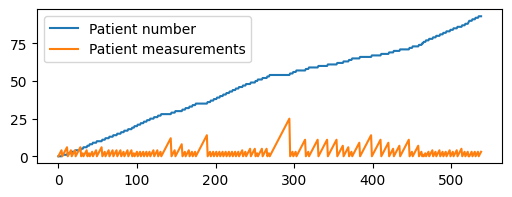

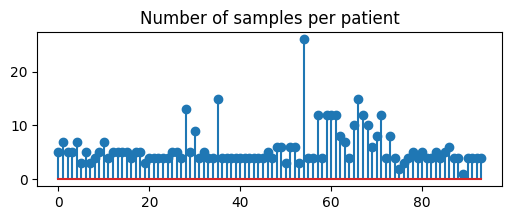

In [36]:
plt.figure(figsize=(6, 2))
plt.plot(patient_no, label="Patient number")
plt.plot(patient_sample, label="Patient measurements")
plt.legend()
plt.show()

plt.figure(figsize=(6, 2))
plt.title("Number of samples per patient")
plt.stem(streak_length(patient_no))
plt.show()

## Export of samples to `data`

In [37]:
# check dimensions
assert len(lesion_assessment) == len(lesion_loc) == Zdata.shape[0]

In [38]:
for p in range(Zdata.shape[0]):
    # print(p, int(Bx[p]), int(Case[p]), "\t", patient_no[p], patient_sample[p])
    np.savez(
        "data/patient_{0:04d}.npz".format(p),
        py_idx=p,
        patient_no=patient_no[p],  # post-processed patient numbering
        patient_sample=patient_sample[p],  # post-processed patient sample numbering
        Zdata=Zdata[p],
        Bx_Case=[int(Bx[p]), int(Case[p])],
        Case=Case[p],
        Avg_Cutpats=Avg_Cutpats[p],
        LesionLoc=lesion_loc[p],
        LesionAssessment=lesion_assessment[p],
        # if the labels are changed here -> also change in toolbox.loading load_data()!
        labels_healthy_vs_cancer=labels_healthy_vs_cancer[p],
        labels_cancer_vs_hbd=labels_cancer_vs_hbd[p],
        labels_WHO=labels_WHO[p],
        Sample=Sample[p],
        Category=Category[p],
    )

___